# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:
# Import necessary libraries
import os, random, json, re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")


# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

Classes found: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']

Class distribution:
  Cardboard      : 461 images
  Food Organics  : 411 images
  Glass          : 420 images
  Metal          : 790 images
  Miscellaneous Trash: 495 images
  Paper          : 500 images
  Plastic        : 921 images
  Textile Trash  : 318 images
  Vegetation     : 436 images

Sampled image sizes (unique): {(524, 524): 90}
Color modes: {'RGB': 90}


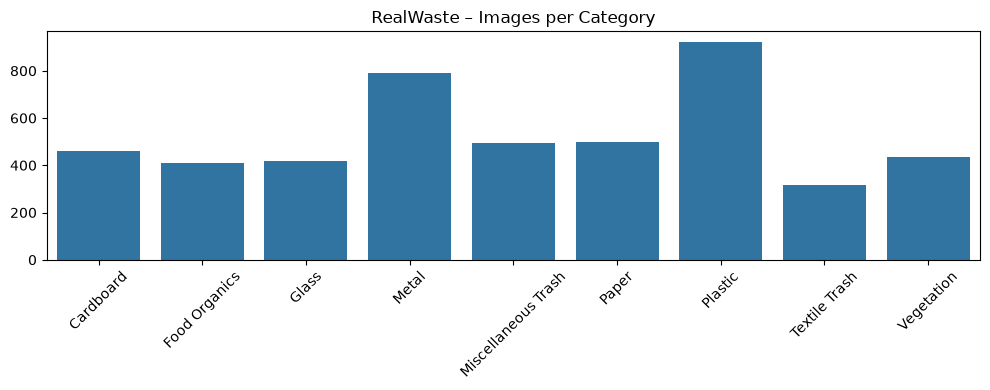

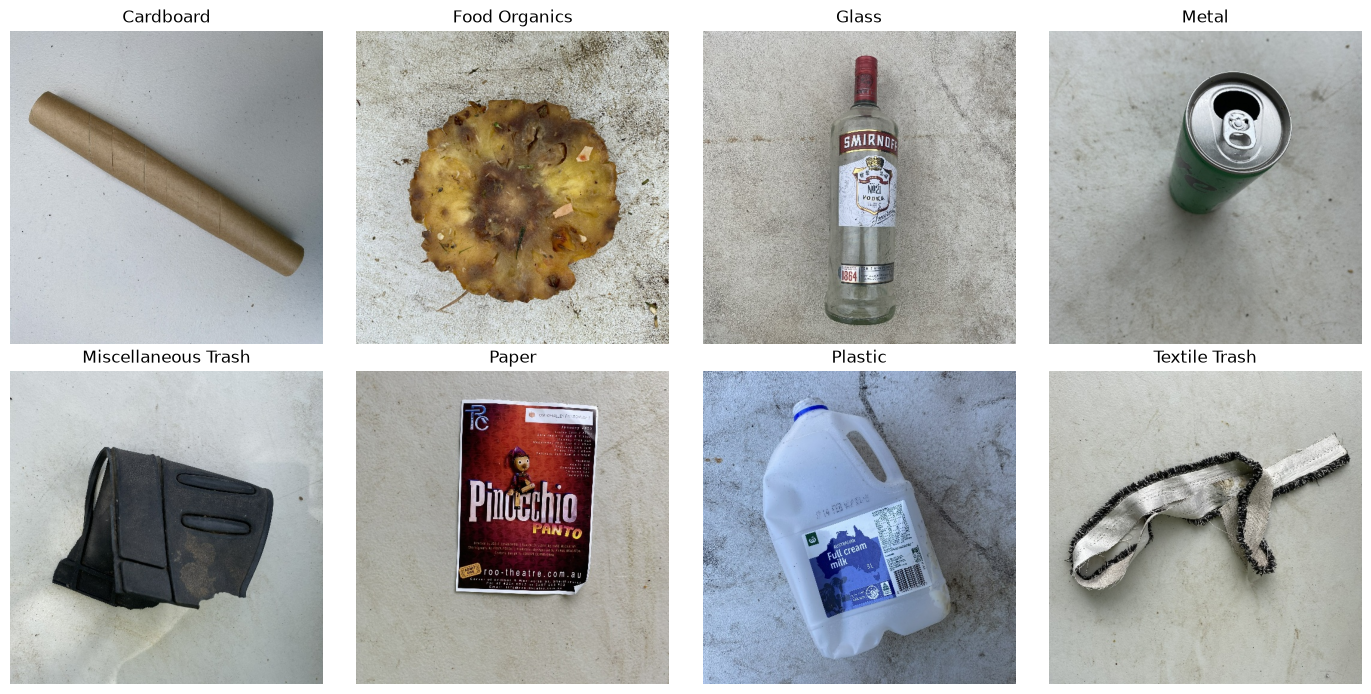


    Observations / challenges:
    - Class imbalance: some classes (e.g., Plastic) have far more samples than others
      (e.g., Brown-glass) → use class_weight or augmentation.
    - Mixed resolutions & lighting → resize to 224×224 & normalise.
    - Backgrounds vary (kitchen counter, outdoor, hands) → rely on transfer learning.
    - Some items visually overlap (paper vs. cardboard; 3 glass colours) → fine-tuning.
    


In [3]:
# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)

import pathlib
data_dir = pathlib.Path(r'C:\Users\HomePC\Downloads\realwaste-main\RealWaste')

if not data_dir.exists():
    print("⚠️  RealWaste/ not found. Please download and unzip the dataset here.")
else:
    #  Dataset structure
    class_dirs = sorted([d for d in data_dir.glob('*') if d.is_dir()])
    class_names_img = [d.name for d in class_dirs]
    counts = {c: len(list((data_dir / c).glob('*.*'))) for c in class_names_img}

    print("Classes found:", class_names_img)
    print("\nClass distribution:")
    for k, v in counts.items():
        print(f"  {k:15s}: {v} images")

    #  Basic image characteristic exploration 
    from PIL import Image
    sample_res = []
    for c in class_names_img:
        imgs = list((data_dir / c).glob('*.*'))[:10]
        for p in imgs:
            try:
                with Image.open(p) as im:
                    sample_res.append((c, im.size, im.mode))
            except Exception:
                pass

    res_df = pd.DataFrame(sample_res, columns=['class', 'size', 'mode'])
    print("\nSampled image sizes (unique):", res_df['size'].value_counts().head(5).to_dict())
    print("Color modes:", res_df['mode'].value_counts().to_dict())

    #  Visualize distribution 
    plt.figure(figsize=(10, 4))
    sns.barplot(x=list(counts.keys()), y=list(counts.values()))
    plt.title("RealWaste – Images per Category")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    #  Show sample images per class 
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, c in zip(axes.ravel(), class_names_img):
        img_path = next((data_dir / c).glob('*.*'))
        with Image.open(img_path) as im:
            ax.imshow(im)
            ax.set_title(c)
            ax.axis('off')
    plt.tight_layout()
    plt.show()

    print("""
    Observations / challenges:
    - Class imbalance: some classes (e.g., Plastic) have far more samples than others
      (e.g., Brown-glass) → use class_weight or augmentation.
    - Mixed resolutions & lighting → resize to 224×224 & normalise.
    - Backgrounds vary (kitchen counter, outdoor, hands) → rely on transfer learning.
    - Some items visually overlap (paper vs. cardboard; 3 glass colours) → fine-tuning.
    """)

### 1.2 Explore Text Datasets

Shape: (5000, 5)
Columns: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']

Nulls per column:
 description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0
dtype: int64

Category distribution:
 category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64

Description word counts:
 count    5000.000000
mean        4.854000
std         1.549956
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        10.000000
Name: n_words, dtype: float64

Total tokens: 25,241 | Unique vocabulary: 309

Sample rows:
                                           description       category                               disposal_in

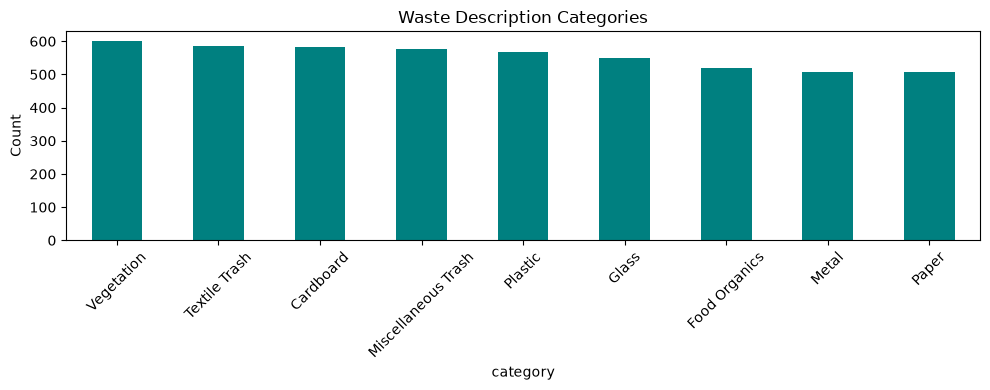


NOTE: The text dataset has 9 categories while RealWaste has 8 image classes.
Mapping we will use in the integrated system:
  Biological (RealWaste) → Food Organics + Vegetation (text)
  *-glass → Glass
  Paper, Cardboard, Metal, Plastic map 1:1.



In [4]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories

desc_df = pd.read_csv('waste_descriptions.csv')
print("Shape:", desc_df.shape)
print("Columns:", list(desc_df.columns))
print("\nNulls per column:\n", desc_df.isna().sum())
print("\nCategory distribution:\n", desc_df['category'].value_counts())

# Vocabulary / structure analysis
desc_df['description'] = desc_df['description'].astype(str)
desc_df['n_words'] = desc_df['description'].str.split().str.len()
print("\nDescription word counts:\n", desc_df['n_words'].describe())

all_tokens = re.findall(r"[a-zA-Z']+", " ".join(desc_df['description'].str.lower()))
vocab = set(all_tokens)
print(f"\nTotal tokens: {len(all_tokens):,} | Unique vocabulary: {len(vocab):,}")

# Short sample
print("\nSample rows:")
print(desc_df[['description', 'category', 'disposal_instruction']].head(5).to_string())

# Distribution plot
plt.figure(figsize=(10, 4))
desc_df['category'].value_counts().plot(kind='bar', color='teal')
plt.title("Waste Description Categories")
plt.ylabel("Count"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# Describe the 9 vs 8 mismatch
print("""
NOTE: The text dataset has 9 categories while RealWaste has 8 image classes.
Mapping we will use in the integrated system:
  Biological (RealWaste) → Food Organics + Vegetation (text)
  *-glass → Glass
  Paper, Cardboard, Metal, Plastic map 1:1.
""")

In [5]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language

with open('waste_policy_documents.json', 'r') as f:
    policy_docs = json.load(f)

print(f"Loaded {len(policy_docs)} policy documents")
print("Sample policy keys:", list(policy_docs[0].keys()))
print("\nSample doc:")
print(json.dumps(policy_docs[0], indent=2)[:900])

# Flatten docs for retrieval
def policy_to_text(p):
    return (f"Policy: {p['policy_type']}\n"
            f"Categories: {', '.join(p['categories_covered'])}\n"
            f"Jurisdiction: {p['jurisdiction']} (effective {p['effective_date']})\n\n"
            f"{p['document_text']}")

policy_texts = [policy_to_text(p) for p in policy_docs]
print("\nTotal policy text characters:", sum(len(t) for t in policy_texts))

Loaded 14 policy documents
Sample policy keys: ['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']

Sample doc:
{
  "policy_id": 1,
  "policy_type": "Textile Trash Recycling Guidelines",
  "categories_covered": [
    "Textile Trash"
  ],
  "effective_date": "2023-11-04",
  "document_text": "TEXTILE RECYCLING GUIDELINES\n\nAcceptable Items:\n- Clean clothing (all conditions)\n- Towels, sheets, and linens\n- Fabric scraps\n- Curtains and cloth napkins\n- Handbags and backpacks made of fabric\n- Soft toys and stuffed animals\n\nNon-Acceptable Items:\n- Wet or moldy textiles\n- Heavily soiled items\n- Carpets and rugs\n- Footwear\n- Items with significant non-textile parts\n\nCollection Method:\nPlace items in dedicated textile recycling bins or donate to local thrift stores.\n\nPreparation Instructions:\n- Ensure all items are clean and dry\n- Remove non-textile components when possible\n- Bag similar items together\n\nBenefits:\nTextile r

### 1.3 Create Data Pipelines

In [7]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path(r'C:\Users\HomePC\Downloads\realwaste-main\RealWaste')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [8]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

import re, string

def clean_text(s: str) -> str:
    s = str(s).lower()
    s = re.sub(r"http\S+|www\.\S+", " ", s)
    s = re.sub(r"[^a-z\s']", " ", s)     # keep letters & apostrophes
    s = re.sub(r"\s+", " ", s).strip()
    return s

desc_df['clean'] = desc_df['description'].apply(clean_text)

# Combine description + disposal instruction + confusion text for richer features
desc_df['feature_text'] = (
    desc_df['description'].fillna('') + " " +
    desc_df['disposal_instruction'].fillna('') + " " +
    desc_df['common_confusion'].fillna('')
).apply(clean_text)

X_text = desc_df['feature_text'].values
y_text = desc_df['category'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_text, y_text, test_size=0.2, random_state=42, stratify=y_text)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42, stratify=y_train)

print("Split sizes:", len(X_train), len(X_val), len(X_test))

# --- Keras tokenisation pipeline (for the DL model) ---
VOCAB_SIZE = 10_000
MAX_LEN    = 40

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

def to_seq(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')

Xtr_seq = to_seq(X_train)
Xva_seq = to_seq(X_val)
Xte_seq = to_seq(X_test)

# Label encoding for the DL model (sklearn handles strings natively, but Keras needs ints)
text_label_names = sorted(np.unique(y_text))
label_to_idx = {l: i for i, l in enumerate(text_label_names)}
idx_to_label = {i: l for l, i in label_to_idx.items()}

ytr_int = np.array([label_to_idx[l] for l in y_train])
yva_int = np.array([label_to_idx[l] for l in y_val])
yte_int = np.array([label_to_idx[l] for l in y_test])

print("Text classes:", text_label_names)

Split sizes: 3400 600 1000
Text classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


In [9]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval

# Sentence-level splitting of the policy documents for finer retrieval.
def split_policy_into_chunks(policy, max_chars=600):
    text = policy['document_text']
    # split on blank lines / headings
    parts = re.split(r"\n\s*\n|(?<=:)\s*\n", text)
    chunks, buf = [], ""
    for p in parts:
        if len(buf) + len(p) < max_chars:
            buf += "\n" + p
        else:
            if buf.strip():
                chunks.append(buf.strip())
            buf = p
    if buf.strip():
        chunks.append(buf.strip())

    return [{
        "policy_id":      policy['policy_id'],
        "policy_type":    policy['policy_type'],
        "categories":     policy['categories_covered'],
        "jurisdiction":   policy['jurisdiction'],
        "chunk":          c
    } for c in chunks]

rag_chunks = []
for p in policy_docs:
    rag_chunks.extend(split_policy_into_chunks(p))

print(f"Total chunks for retrieval: {len(rag_chunks)}")

# Fit a TF-IDF vectoriser over chunks + policy overview text.
rag_corpus = [c['chunk'] for c in rag_chunks] + policy_texts
rag_vec = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=1)
rag_matrix = rag_vec.fit_transform(rag_corpus)

# First len(rag_chunks) rows correspond to chunk-level vectors
rag_chunk_matrix = rag_matrix[:len(rag_chunks)]
print("RAG embedding matrix shape:", rag_chunk_matrix.shape)

Total chunks for retrieval: 27
RAG embedding matrix shape: (27, 960)


## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [ ]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier

# Your code here

### 2.2 Implement CNN Model with Transfer Learning

In [ ]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Your code here

### 2.3 Train and Evaluate the Model

In [ ]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Your code here

In [ ]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here

### 2.4 Fine-tune the Model

In [ ]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Your code here

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [ ]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Your code here

### 3.2 Implement Text Classification Model

In [ ]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

# Your code here

### 3.3 Train and Evaluate the Model

In [ ]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

# Your code here

In [ ]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here

### 3.4 Create Classification Function

In [ ]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # Your code here
    pass

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [ ]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Your code here

### 4.2 Implement RAG-based System

In [ ]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

# Your code here

### 4.3 Adjust and Evaluate the System

In [ ]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# Your code here

In [ ]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

# Your code here

### 4.4 Create Instruction Generation Function

In [ ]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    # Your code here
    pass

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [ ]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

# Your code here

### 5.2 Implement Integrated Assistant

In [ ]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    # Your code here
    pass

### 5.3 Evaluate the Integrated System

In [ ]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# Your code here

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.